<div class="alert alert-info">
<h1>Multiple Regression</h1>
<h4>Homework to Environmental Statistics 1</h4>
<h4>Your Name is here</h4>
</div>

This weeks exercises will practice the content of the lecture and tutorials and extend them in different ways:
-  plotting: 3D, value-dependent symbol sizes and colours;
-  interaction with quadratic terms.<br>

Do not expect to be able to solve these exercises based on the lecture and tutorial alone! As always, the literature provided and various internet resources are your friend.


##  1 Exercise   1 (10 points):   Seed germination
A Biologist analyzed an experiment to determine the effect of moisture content on seed germination. Eight boxes of 100 seeds each were treated with the same moisture level. 4 boxes were covered and 4 left uncovered. The process was repeated at 6 different moisture levels (nonlinear scale). Data are in **faraway**’s seeds.
1. Plot the data (2 point), using different symbols or colours for covered levels and a legend, and with properly labelled axes.
2. Analyse the data for a statistical interaction (3 points).
3. Add regression lines including 95% confidence interval to the plot (3 point).
4. Interpret your findings, using both figure and analysis (2 points).

In [35]:
# needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from mpl_toolkits.mplot3d import Axes3D

In [3]:
# load data
seeds = pd.read_csv("seeds.csv")
seeds.head()

,germ,moisture,covered
0,22.0,1,no
1,41.0,3,no
2,66.0,5,no
3,82.0,7,no
4,79.0,9,no


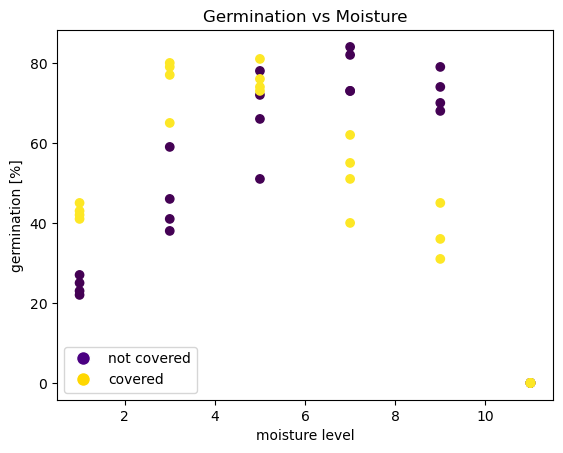

In [4]:
# Create a scatter plot
plt.scatter(seeds['moisture'], seeds['germ'], c=(seeds['covered'] == "yes"), cmap='viridis', marker='o')

# Set labels and title
plt.xlabel('moisture level')
plt.ylabel('germination [%]')
plt.title('Germination vs Moisture')

# Create a custom legend
plt.legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='indigo', markersize=10, label='not covered'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gold', markersize=10, label='covered')
])

plt.show()

## 1.2    Analysis
It is crucial to realise, from the plot, that the effect of moisture is non-linear. This cannot be fit well with an interaction alone, but it requires a quadratic effect!

In [5]:
fm = sm.GLM.from_formula(formula='germ ~ moisture*covered', data=seeds, 
                         family=sm.families.Gaussian()).fit()

print(fm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   germ   No. Observations:                   47
Model:                            GLM   Df Residuals:                       43
Model Family:                Gaussian   Df Model:                            3
Link Function:               Identity   Scale:                          677.60
Method:                          IRLS   Log-Likelihood:                -217.79
Date:                Tue, 28 Oct 2025   Deviance:                       29137.
Time:                        14:03:49   Pearson chi2:                 2.91e+04
No. Iterations:                     3   Pseudo R-squ. (CS):             0.2014
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

In [6]:
print('AIC :', fm.aic)

AIC : 443.5715449664068


In [7]:
# Define the formula
formula = "germ ~ (moisture + I(moisture**2)) * covered"

# Fit the GLM with the specified formula
fm2 = sm.GLM.from_formula(formula, data=seeds, family=sm.families.Gaussian()).fit()

# Get a summary of the model
print(fm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                   germ   No. Observations:                   47
Model:                            GLM   Df Residuals:                       41
Model Family:                Gaussian   Df Model:                            5
Link Function:               Identity   Scale:                          129.31
Method:                          IRLS   Log-Likelihood:                -177.74
Date:                Tue, 28 Oct 2025   Deviance:                       5301.8
Time:                        14:03:52   Pearson chi2:                 5.30e+03
No. Iterations:                     3   Pseudo R-squ. (CS):             0.9938
Covariance Type:            nonrobust                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [8]:
print('AIC :', fm2.aic)

AIC : 367.48591040813875


The `anova_lm()` function from the `statsmodels.stats.anova` module fails to work with the GLM results from `statsmodels.formula.api.GLM.from_formula()`, So we switch to the `ols()` function from the `statsmodels.formula.api` module, so that ANOVA summaries can be generated easily.

In [9]:
fm3 = ols("germ ~ (moisture + I(moisture**2)) * covered", data=seeds).fit()
print(fm3.summary())

# Get the ANOVA summary
anova_results = anova_lm(fm3)

# Print the ANOVA summary
anova_results


                            OLS Regression Results                            
Dep. Variable:                   germ   R-squared:                       0.853
Model:                            OLS   Adj. R-squared:                  0.836
Method:                 Least Squares   F-statistic:                     47.75
Date:                Tue, 28 Oct 2025   Prob (F-statistic):           4.87e-16
Time:                        14:04:06   Log-Likelihood:                -177.74
No. Observations:                  47   AIC:                             367.5
Df Residuals:                      41   BIC:                             378.6
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

,df,sum_sq,mean_sq,F,PR(>F)
covered,1.0,1.100871,1.100871,0.008513,9.269349e-01
moisture,1.0,4053.996845,4053.996845,31.350495,1.605646e-06
moisture:covered,1.0,2983.584107,2983.584107,23.072746,2.106204e-05
I(moisture ** 2),1.0,23181.782370,23181.782370,179.270086,1.468329e-16
I(moisture ** 2):covered,1.0,653.018344,653.018344,5.049942,3.007194e-02
Residual,41.0,5301.794059,129.312050,NaN,NaN


## 1.3    Regression plot
Compute predictions for each cover type, incl. standard errors.

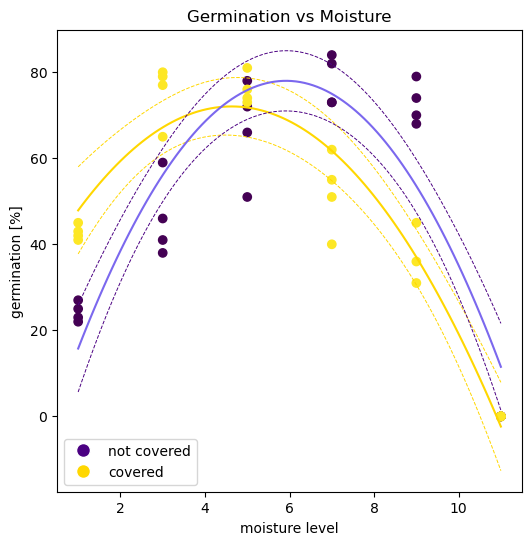

In [10]:
newMoistUnco = np.linspace(1, 11, num=100) # numpy.ndarray
newMoistCo = np.linspace(1, 11, num=100) # numpy.ndarray


# Convert to a dataframe
newMoistCo_df = pd.DataFrame(list(newMoistCo), columns=["moisture"])
newMoistCo_df['covered'] = "yes"

newMoistUnco_df = pd.DataFrame(list(newMoistUnco), columns=["moisture"])
newMoistUnco_df['covered'] = "no"

# Prediction
'''
mean_ci refers to the confidence interval and obs_ci refers to the prediction interval.
'''
predsCovered = fm2.get_prediction(newMoistCo_df).summary_frame(alpha=0.05)
predsUncovered = fm2.get_prediction(newMoistUnco_df).summary_frame(alpha=0.05)

#predsCovered.head()

# main plot
fig, ax = plt.subplots(figsize=(6, 6))

# Create a scatter plot
ax.scatter(seeds['moisture'], seeds['germ'], c=(seeds['covered'] == "yes"), cmap='viridis', marker='o')

# Covered
plt.plot(newMoistCo_df['moisture'], predsCovered['mean'], color='gold')
plt.plot(newMoistCo_df['moisture'], predsCovered['mean_ci_lower'],
         color='gold', linestyle='--',linewidth=0.7)
plt.plot(newMoistCo_df['moisture'], predsCovered['mean_ci_upper'], 
         color='gold', linestyle='--',linewidth=0.7)

# Uncovered
plt.plot(newMoistUnco_df['moisture'], predsUncovered['mean'], color='mediumslateblue', label='After')
plt.plot(newMoistUnco_df['moisture'], predsUncovered['mean_ci_lower'],
         color='indigo', linestyle='--',linewidth=0.7)
plt.plot(newMoistUnco_df['moisture'], predsUncovered['mean_ci_upper'],
         color='indigo', linestyle='--',linewidth=0.7)

# Set labels and title
plt.xlabel('moisture level')
plt.ylabel('germination [%]')
plt.title('Germination vs Moisture')

# Create a custom legend
plt.legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='indigo', markersize=10, label='not covered'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gold', markersize=10, label='covered')
])

plt.show()

## 1.4 Interpret plot

The figure represents germination rate as a function of soil moisture, with non-linear effects specific to the covered treatment. Dashed lines are 95% confidence intervals for each group.

## 2 Exercise  2:   SAT scores (14 points)
Public schools in the USA (as everywhere else) are under scrutiny for their performance: do pupils get better grades when the teachers are better paid? Using 1994/1995 data, we shall compare the 50 states in the total performance of pupils (the SAT score `total`) as a function of proportion of eligible pupils (`takers`) and teacher's average annual `salary`. 

  1. Plot the data, using colour *and* symbol size to indicate SAT scores and putting the two predictors onto x- and y- axis. This imitates a 3D-plot! (Hint: For the colour option you may want to re-scale the response values to between 0.2 and 1. That is similar to rescaling to [0,1], times the new intended range (i.e. 0.8) plus the offset (0.2). This is also about learning how to find help online.)(Hint 2: For colour, play with the `rgb` function, which has 4 arguments: red, green, blue and transparency. That last argument is one option for adjusting colour.) (**4 points**)
  
  2. Based on the plot, can you make any statement about the effect of takers and salary on SAT-scores? (**2 points**)
  
  3. Analyse total SAT-score for effects of proportion of takers and salary, and their interaction. Describe, briefly, what you find. As always, do **not** use the names of the variables in your answer, i.e. no "there is an effect of `takers`", but "there is an effect of the number of pupils taking the exam"! (And be more specific than that, of course.) (**4 points**)
  
  4. Make a "3D"-plot of the model with interaction, i.e. either an actual 3D-plot, or a "topographic map"-like plot (with contours). Indiate where the data are (e.g. as little crosses). Re-examing your interpretation from the previous step and formulate what the interaction of the two predictors means to pupil's SAT-scores. (Hint: Do not worry about prediction error. It is difficult to visualise that in 3D.) (**4 points**)


## 2.1   Plotting  

In [11]:
# load data
sat = pd.read_csv("sat.csv")
sats = sat.iloc[: , 1:]
sats.index = sat['state']

sats.head()

,expend,ratio,salary,takers,verbal,math,total
state,,,,,,,
Alabama,4.405,17.2,31.144,8,491,538,1029
Alaska,8.963,17.6,47.951,47,445,489,934
Arizona,4.778,19.3,32.175,27,448,496,944
Arkansas,4.459,17.1,28.934,6,482,523,1005
California,4.992,24.0,41.078,45,417,485,902


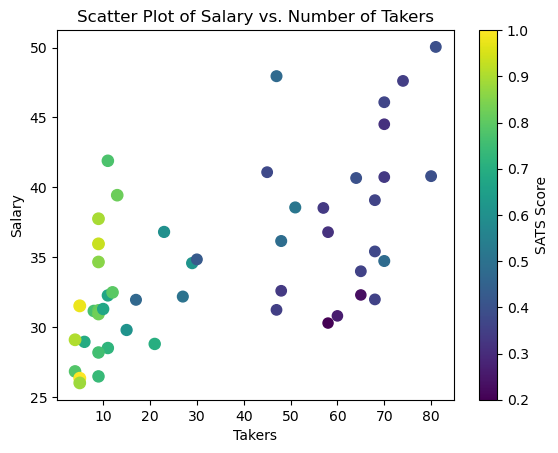

In [12]:
# Normalize using:
satrange = (sats['total'] - min(sats['total'])) / (max(sats['total']) - min(sats['total'])) * 0.8 + 0.2

#print(satrange)

# Create the scatter plot
plt.scatter(sats['takers'], sats['salary'], c=satrange, s=sats['total']/16, cmap='viridis')

# Add labels and title
plt.xlabel('Takers')
plt.ylabel('Salary')
plt.title('Scatter Plot of Salary vs. Number of Takers')

# Add colorbar
plt.colorbar(label='SATS Score')

plt.show()

##  2.2   Visual interpretation
Only when a low proportion (<40%) are taking the exam is the SAT score high. Salary seems to play no role.


##  2.3   Analysis

In [13]:
fm4 = ols("total ~ takers * salary", data=sats).fit()
print(fm4.summary())

                            OLS Regression Results                            
Dep. Variable:                  total   R-squared:                       0.823
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     71.14
Date:                Tue, 28 Oct 2025   Prob (F-statistic):           2.64e-17
Time:                        14:04:36   Log-Likelihood:                -242.95
No. Observations:                  50   AIC:                             493.9
Df Residuals:                      46   BIC:                             501.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      1082.3456     54.352     19.914

The model explains quite a lot of the variation (>80%). The effect of proportion of pupils taking the exam is strong and negative. With higher salaries, SAT-scores decrease slightly less with proportion of pupils taking the exam.


## 2.4   3D-plotting of fitted model


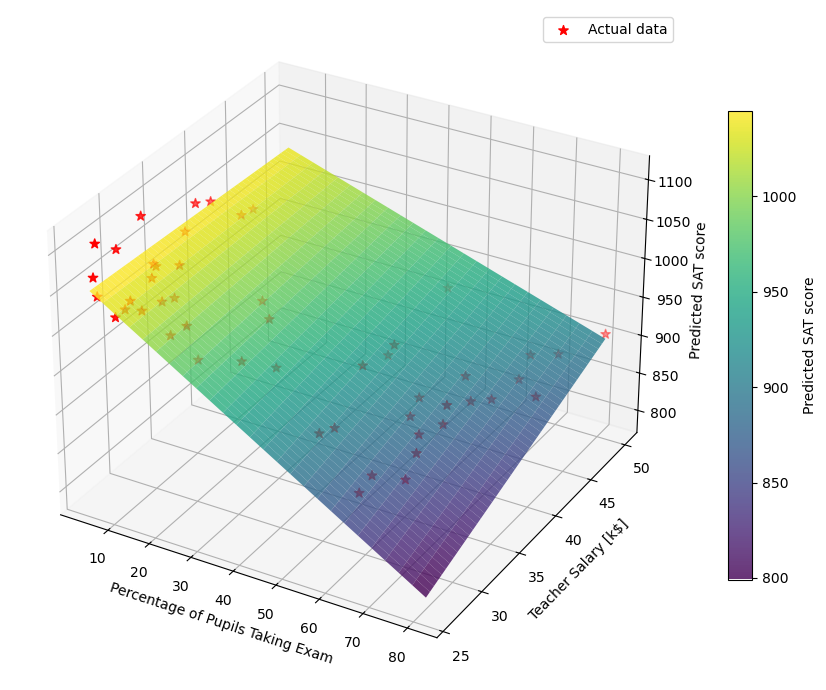

In [57]:
newTakers = np.linspace(min(sats['takers']), max(sats['takers']), num=51) # numpy.ndarray
newSalary = np.linspace(min(sats['salary']), max(sats['salary']), num=49) # numpy.ndarray

# Create a grid of new data points
x, y = np.meshgrid(newTakers, newSalary)

# Predict using the model
z = fm4.predict(pd.DataFrame({"takers": x.flatten(), "salary": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

# Create the 3D surface plot
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')


# Plot the surface
surf = ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)

# overlay actual data points
ax.scatter(sats['takers'],sats['salary'],sats['total'],
          color='red', marker='*', label='Actual data', s=50, depthshade=True)

# colour bar
fig.colorbar(surf, ax=ax, aspect=20, shrink=0.7, label='Predicted SAT score')

# Set labels

ax.set_zlabel('Predicted SAT score')
ax.set_xlabel("Percentage of Pupils Taking Exam")
ax.set_ylabel("Teacher Salary [k$]")

ax.legend()
plt.tight_layout()
plt.show()


Or as colour contour plot:

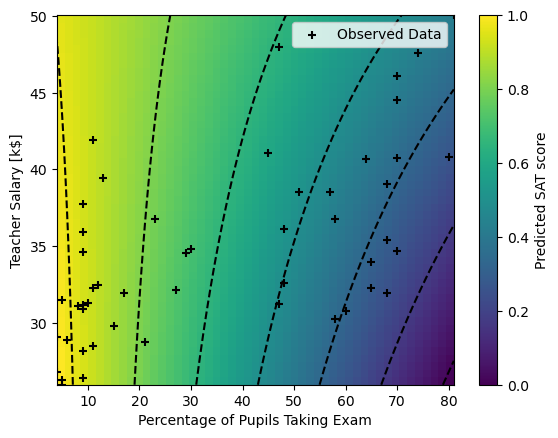

In [69]:
# Assuming 'newTakers', 'newSalary', and 'z' have been defined
# Predict using the model
z = fm4.predict(pd.DataFrame({"takers": x.flatten(), "salary": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

# Create the filled color representation
plt.imshow(z, extent=[min(newTakers), max(newTakers), min(newSalary), max(newSalary)], 
           origin='lower', cmap='viridis', aspect='auto')

# Add contour lines
contours = plt.contour(newTakers, newSalary, z, colors='black', linestyles='--')


# Add scattered points from 'sat'
plt.scatter(sats['takers'], sats['salary'], marker='+', color='black', label='Observed Data')
plt.colorbar(label='Predicted SAT score')

# Add labels and title
plt.xlabel("Percentage of Pupils Taking Exam")
plt.ylabel("Teacher Salary [k$]")

# Add legend
plt.legend()

plt.show()

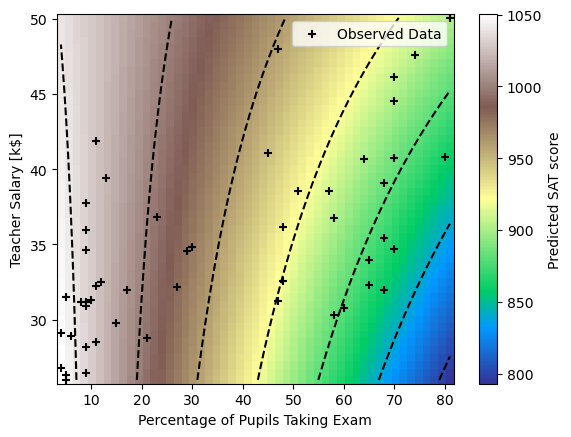

In [73]:
# We can also use plt.pcolormesh() instead of imshow()

z = fm4.predict(pd.DataFrame({"takers": x.flatten(), "salary": y.flatten()}))

# Reshape the predictions back to the grid shape
z = z.values.reshape(x.shape)

plt.pcolormesh(newTakers, newSalary, z, cmap='terrain', shading='auto')
plt.colorbar(label='Predicted SAT score')

# Add contour lines
contours = plt.contour(newTakers, newSalary, z, colors='black', linestyles='--')

# Add scattered points from 'sat'
plt.scatter(sats['takers'], sats['salary'], marker='+', color='black', label='Observed Data')

# Add labels and title
plt.xlabel("Percentage of Pupils Taking Exam")
plt.ylabel("Teacher Salary [k$]")

# Add legend
plt.legend()

plt.show()

Re-interpret: (The statistical interaction is visible as non-straight lines in the plot.) There seems to be no effect of teacher's salary as long as less than half of the eligible students take the exam (the lines are vertical here). At very high percentages of exams (>60%), better paid teachers yield slightly higher SAT-scores. 
